# Entscheidungsbaum - MNIST

In diesem Notebook wird ein Entscheidungsbaum zur Klassifikation handgeschriebener Ziffern aus dem MNIST-Datensatz trainiert und ausgewertet.

**Vorgehen:**
1. Daten laden & vorbereiten
2. Entscheidungsbaum mit Standardparametern trainieren und analysieren
3. Hyperparameter mit RandomizedSearchCV optimieren
4. Optimierten Baum trainieren und mit dem Standardmodell vergleichen

## ROC Helper-Funktion

Die Funktion habe ich aus den Vorlesungsinhalten übernommen zur Visualisierung der ROC-Kurven.

In [1]:
def plot_res_roc(fpr, tpr, is_data_list=False, data_labels=None,
                 data_style=None, pos_legend='lower right'):
    """
    Plot one or multiple ROC (Receiver Operating Characteristic) curves.

    Parameters
    ----------
    fpr : array-like or list of array-like
        False Positive Rates. Either a single array or a list of arrays.
    tpr : array-like or list of array-like
        True Positive Rates. Must correspond to `fpr` (single array or list).
    is_data_list : bool, optional
        If True, multiple ROC curves are plotted (list mode).
        If False, only one ROC curve is plotted.
    data_labels : list of str, optional
        Labels for the legend entries (one label per curve).
    data_style : list of [marker_size, line_width], optional
        Plot styles for each curve. If None, default styles are applied.
    pos_legend : str, optional
        Legend position (e.g., 'lower right', 'upper left').

    Notes
    -----
    The function also plots the diagonal line representing a random classifier
    for reference.
    """

    xval = np.arange(0, 1, 0.0001)

    markers = ["o", "v", "s", "D", "X"]
    fig = plt.figure(figsize=(6, 6), dpi=100)
    ax = plt.subplot(111)

    # Set default styles if none are provided
    if data_style is None:
        data_style = []
        if is_data_list:
            # Same default style for each curve
            for i in range(1, len(fpr) + 1):
                data_style.append([10, 0])
        else:
            data_style = [[6, 0]]  # Default style for a single curve

    # Plot multiple ROC curves
    if is_data_list:
        for i in range(len(fpr)):
            ax.plot(
                fpr[i],
                tpr[i],
                label=data_labels[i],
                lw=data_style[i][1],
                marker=markers[0],
                markersize=data_style[i][0],
            )
    else:
        # Plot a single ROC curve
        ax.plot(
            fpr,
            tpr,
            label=data_labels[0],
            lw=data_style[0][1],
            marker=markers[0],
            markersize=data_style[0][0],
        )

    # Reference line (random classifier)
    ax.plot(xval, xval, lw=1, ls="--", color='black')

    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), fancybox=True, fontsize=12)
    bbox_to_anchor=(1, 0.5)
    plt.xlabel('FPR', fontsize=20)
    plt.ylabel('TPR', fontsize=20)
    plt.tick_params(axis='both', which='major', labelsize=15)
    plt.grid(True)

    plt.ylim(-.02, 1.02)
    plt.xlim(-.02, 1.02)

## Import

Umsetzung Peerfeedback: Störende Warnmeldungen ausblenden. Das wurde nach dem fertigstellen und prüfen der Warnmeldungen hinzugefügt.

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize
import graphviz

# Daten laden und vorbereiten
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Die Pixelbilder sind 3D und müssen zunächst in ein 2D Format reshaped werden, damit der Entscheidungsbaum diese verwenden kann.
X_train = x_train.reshape(x_train.shape[0], -1)
X_test = x_test.reshape(x_test.shape[0], -1)

# Normalisieren: Für Entscheidungsbaum nicht notwendig, aber für vereinheitlichung und das Ensemble eingebaut.
X_train = X_train / 255.0
X_test = X_test / 255.0

### PCA – Verworfen

PCA wurde als Vorverarbeitungsschritt getestet, hat die Accuracy jedoch verschlechtert und wird daher nicht verwendet.

**Begründung:**

Entscheidungsbäume splitten immer nach einzelnen Features. Im originalen Pixelraum ist jedes Feature ein konkreter Pixel. Die PCA fasst alle Pixel zu neuen Komponenten zusammen, die keine anschauliche Bedeutung mehr haben. Der Baum kann damit schlechter arbeiten.

In [4]:
# from sklearn.decomposition import PCA
#
# pca = PCA(n_components=0.95, random_state=42)
#
# X_train = pca.fit_transform(X_train)
# X_test  = pca.transform(X_test)
#
# n_components = pca.n_components_
# print(f"Ursprüngliche Dimensionen : 784")
# print(f"PCA-Komponenten (95% Var.): {n_components}")
# print(f"Datenkompression          : {n_components / 784:.1%} der ursprünglichen Features")

## Entscheidungsbaum mit Standardparametern

Zunächst wird ein Entscheidungsbaum mit den Default-Einstellungen von sklearn trainiert. Das dient als Grundlage, mit der das später optimierte Modell verglichen wird.

### Standardmodell Trainieren

In [5]:
# Standardparameter Modell

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Standardparmeter:" ,tree.get_params())
print()

# Gewählte Parameter
print("Tatsächliche Tiefe des Baums:", tree.get_depth())
print("Anzahl der Blätter:", tree.get_n_leaves())
print()

# Ergebnisse Test & Train mit Standardparametern
y_train_pred = tree.predict(X_train)
train_accuracy_std = accuracy_score(y_train, y_train_pred)

y_pred = tree.predict(X_test)
test_accuracy_std = accuracy_score(y_test, y_pred)

print("Accuracy Training:", round(train_accuracy_std, 4))
print("Accuracy Test:", round(test_accuracy_std, 4))
print("Differenz:", round(train_accuracy_std - test_accuracy_std, 4))
print()

Standardparmeter: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

Tatsächliche Tiefe des Baums: 50
Anzahl der Blätter: 3936

Accuracy Training: 1.0
Accuracy Test: 0.8754
Differenz: 0.1246



Man erkennt, dass der Baum mit 59 eine sehr große Tiefe hat. Außerdem zeigt die 100 % Trainingsgenauigkeit im Vergleich zur niedrigeren Testgenauigkeit ein klares Overfitting.

**Visualisierung des Baums**

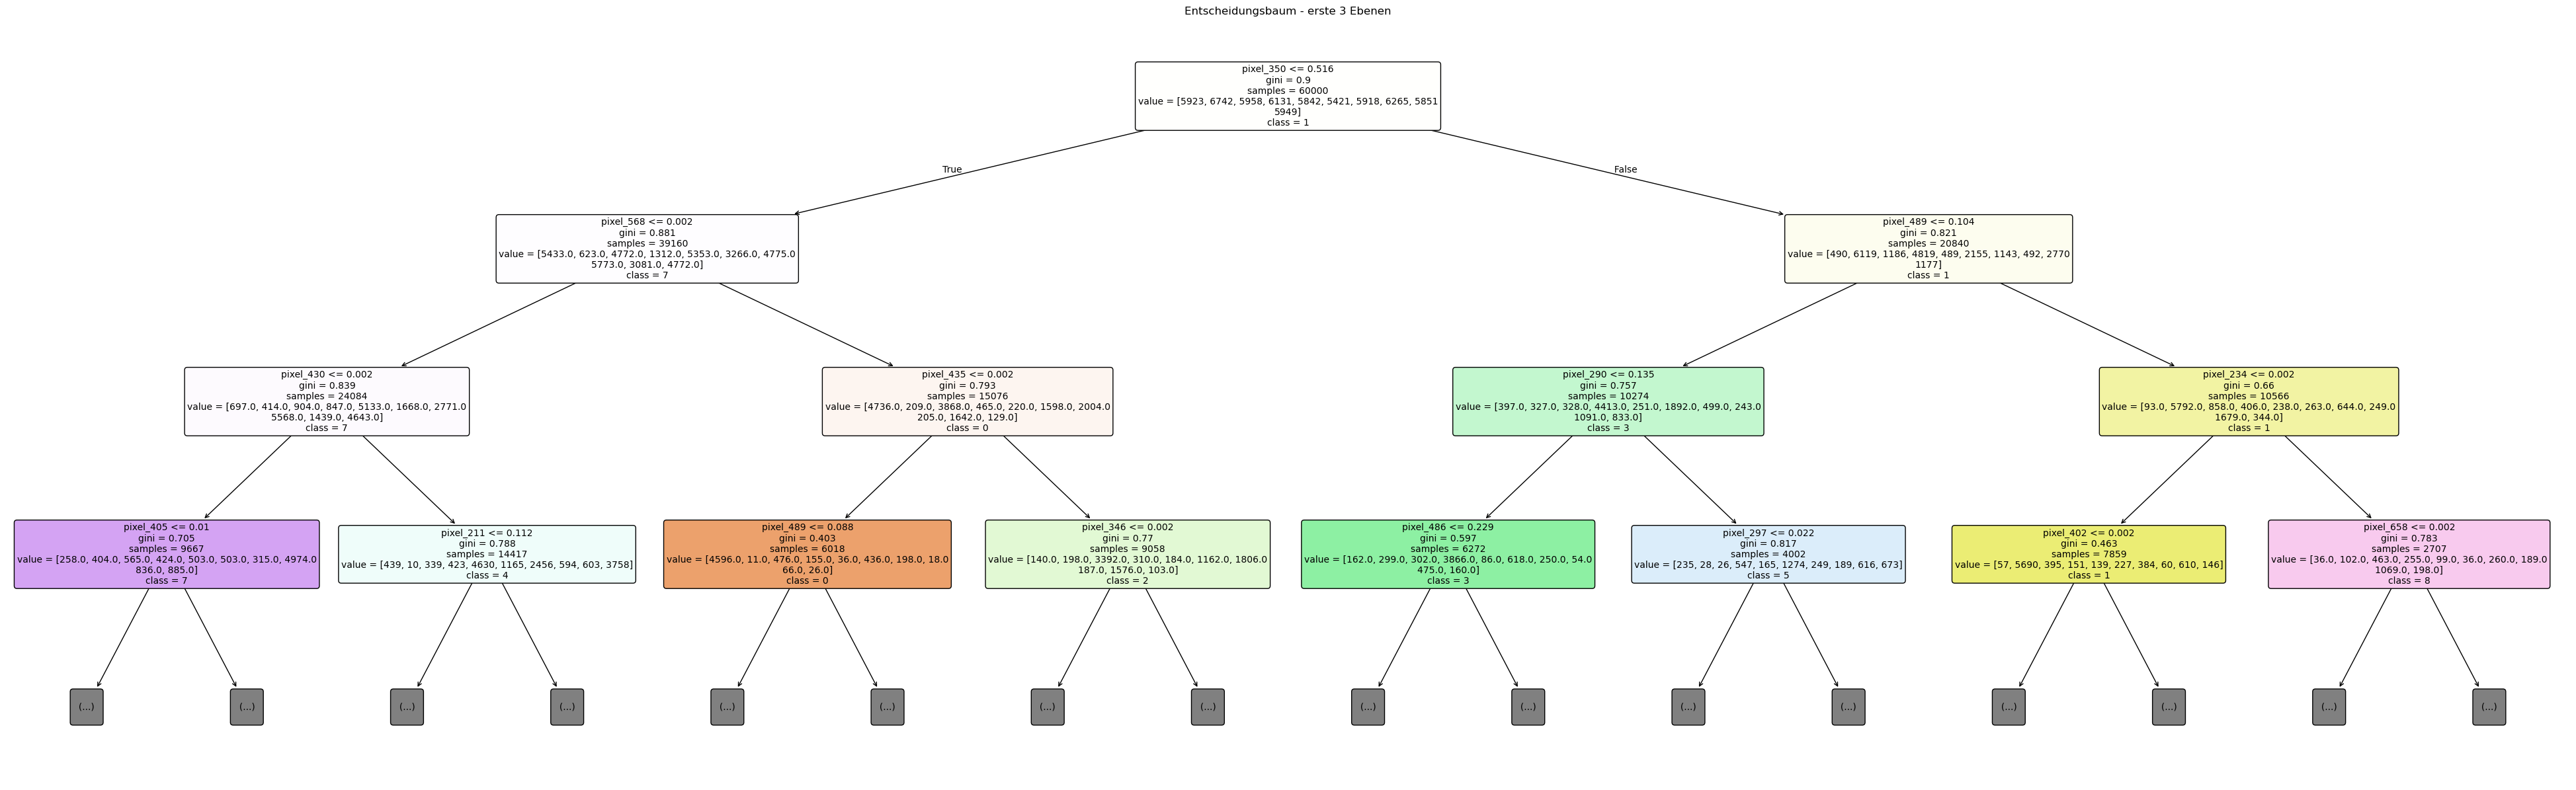

In [6]:
# Nur die ersten 3 Ebenen anzeigen, da es sonst nicht mehr sinvoll darstellbar ist.
plt.figure(figsize=(50, 15))
plot_tree(tree, 
          max_depth=3,       
          feature_names=[f'pixel_{i}' for i in range(784)], 
          class_names=[str(i) for i in range(10)],          
          filled=True,         
          rounded=True,         
          fontsize=10)
plt.title('Entscheidungsbaum - erste 3 Ebenen')
plt.savefig("entscheidungsbaum.jpg", bbox_inches="tight")
plt.show()

### Genauere Analyse des Standardmodells

#### Classification Report

Der Classification Report zeigt Precision, Recall und F1-Score pro Klasse:
- Precision: Wie viele der als Klasse X vorhergesagten Samples sind tatsächlich X?
- Recall: Wie viele der echten Klasse X wurden korrekt erkannt?
- F1-Score: Harmonisches Mittel aus Precision und Recall.

In [7]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.912     0.933     0.922       980
           1      0.949     0.955     0.952      1135
           2      0.863     0.859     0.861      1032
           3      0.831     0.852     0.842      1010
           4      0.861     0.874     0.868       982
           5      0.850     0.830     0.839       892
           6      0.895     0.883     0.889       958
           7      0.912     0.900     0.906      1028
           8      0.819     0.806     0.813       974
           9      0.847     0.846     0.847      1009

    accuracy                          0.875     10000
   macro avg      0.874     0.874     0.874     10000
weighted avg      0.875     0.875     0.875     10000



Die schwächsten Klassen sind 8, 5 und 3. diese Ziffern werden am häufigsten verwechselt, vermutlich weil sie sich optisch ähneln. Klasse 1 erzielt den besten Wert, da die Ziffer „1" optisch sehr eindeutig ist.

#### Confusion Matrix (verworfen)

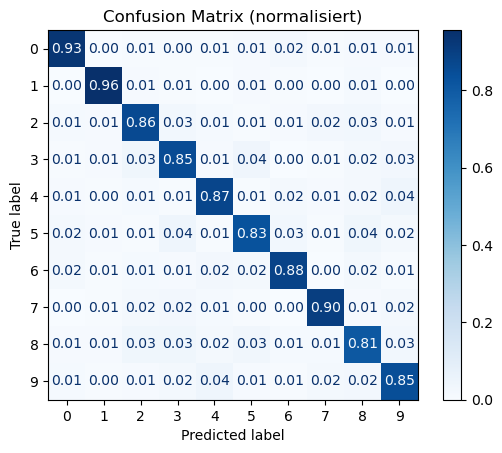

In [8]:
# Verworfen, da aus den Visualisierungen keine klaren Fazite gezogen werden können.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Normalisiert nach wahren Klassen (Recall)
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=tree.classes_)
disp.plot(cmap='Blues', values_format='.2f')  
plt.title('Confusion Matrix (normalisiert)')
plt.savefig("Confusion Matrix (normalisiert).jpg", bbox_inches="tight")
plt.show()

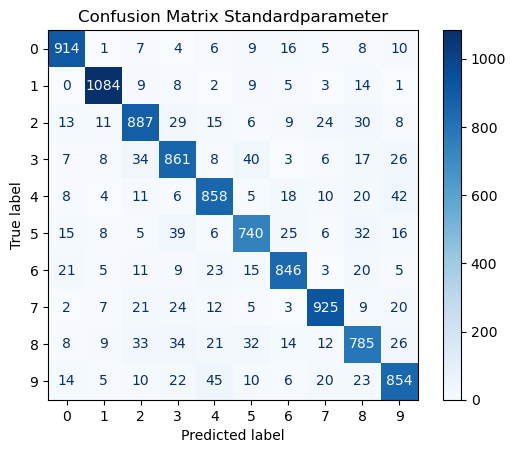

In [9]:
# Confusion Matrix nicht normalisiernd sondern mit absoluten Werten, da Klassen relativ ähnlich verteilt sind.
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Confusion Matrix Standardparameter")
plt.savefig("Confusion Matrix Standardparameter.jpg", bbox_inches="tight")
plt.show()

#### TSNE Grafik

t-SNE (t-distributed Stochastic Neighbor Embedding) reduziert die Daten auf 2 Dimensionen zur Visualisierung.  
Gut trennbare Cluster deuten darauf hin, dass die Klassen im Feature-Raum besser unterscheidbar sind.

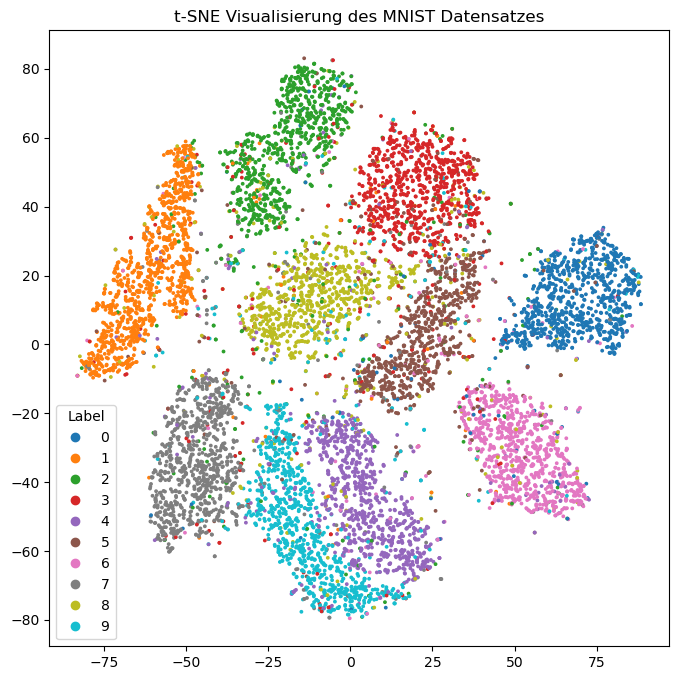

In [8]:
#TSNE Grafik (Klassifizierungen visualisieren)
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(X_test)

plt.figure(figsize=(8,8))
scatter = plt.scatter(
    X_embedded[:,0],
    X_embedded[:,1],
    c=y_pred,
    cmap="tab10",
    s=3
)

plt.legend(*scatter.legend_elements(), title="Label")
plt.title("t-SNE Visualisierung des MNIST Datensatzes")
plt.savefig("t-SNE Visualisierung des MNIST Datensatzes.jpg", bbox_inches="tight")
plt.show()

Die meisten Ziffern bilden erkennbare Cluster, was zeigt, dass MNIST grundsätzlich gut trennbar ist. Überlappungen zwischen benachbarten Clustern (besonders bei 4/9 und 3/5/8) erklären, warum gerade diese Klassen im Classification Report niedrigere Scores erzielen.

#### Feature Importance

Die Feature Importance zeigt, welche Pixel der Baum beim Splitten am häufigsten und stärksten genutzt hat.  

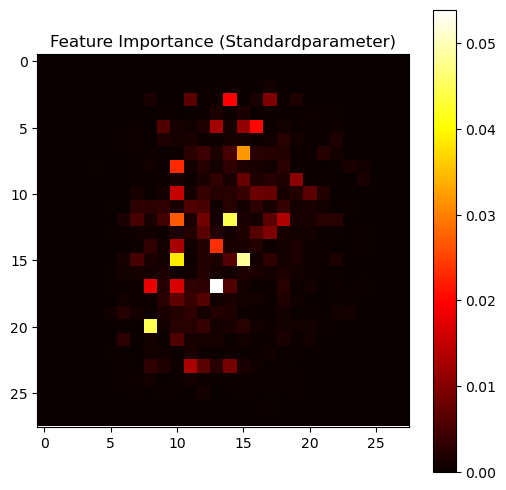

In [9]:
# Importance einzenlner Pixel
importances = tree.feature_importances_
plt.figure(figsize=(6,6))
plt.imshow(importances.reshape(28,28), cmap='hot')
plt.colorbar()
plt.title('Feature Importance (Standardparameter)')
plt.savefig("Feature Importance (Standardparameter).jpg", bbox_inches="tight")
plt.show()

Vor allem die mittleren Pixel sind von hoher Bedeutung bei der Klassifizierung. Dies ergibt Sinn, da die Ziffern meist zentriert geschrieben werden.

#### ROC-Kurven

Die ROC-Kurve (Receiver Operating Characteristic) zeigt den Kompromiss zwischen True Positive Rate (Recall) und False Positive Rate für jeden Klassifizierungsschwellwert.

Da MNIST 10 Klassen hat, wird One-vs-Rest verwendet: jede Ziffer wird nacheinander als positiv betrachtet, die restlichen 9 als negativ.  
Der AUC (Area Under Curve) ist ein zusammenfassender Score. Je näher dieser an 1 ist, desto besser.

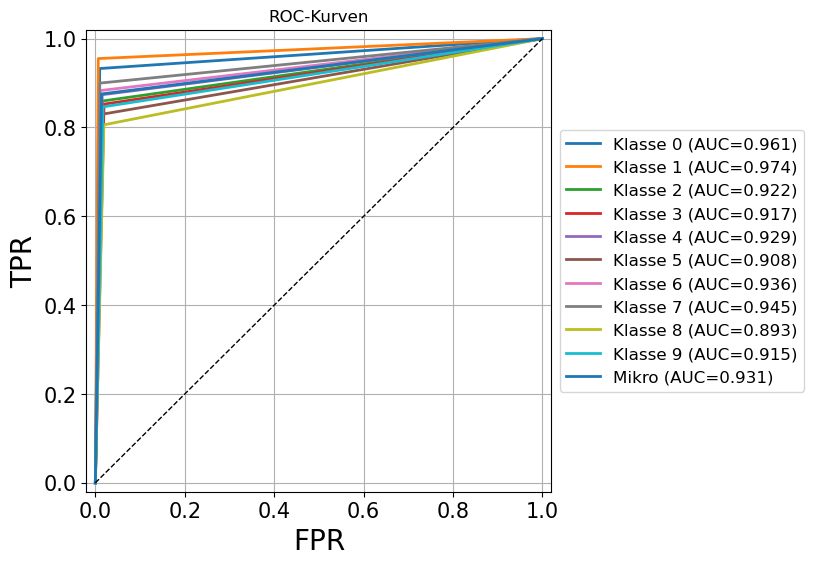

In [10]:
from sklearn.metrics import roc_curve, auc

# Wahrscheinlichkeiten
y_proba = tree.predict_proba(X_test)
n_classes = len(tree.classes_)

# Listen für ROC-Kurven
fpr_list, tpr_list, labels = [], [], []

# Für jede Klasse One-vs-Rest ROC
for i in range(n_classes):
    y_bin = (y_test == i).astype(int)
    fpr_i, tpr_i, _ = roc_curve(y_bin, y_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    fpr_list.append(fpr_i)
    tpr_list.append(tpr_i)
    labels.append(f'Klasse {i} (AUC={auc_i:.3f})')

# Mikro-Mittelung
y_test_bin = np.eye(n_classes)[y_test]  # One-Hot
fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_proba.ravel())
auc_micro = auc(fpr_micro, tpr_micro)
fpr_list.append(fpr_micro)
tpr_list.append(tpr_micro)
labels.append(f'Mikro (AUC={auc_micro:.3f})')

# Plot mit unsichtbaren Markern (markersize=0)
# Erzeuge data_style: [markersize, linewidth] – markersize=0, linewidth=2
data_style = [[0, 2] for _ in range(len(fpr_list))]

plot_res_roc(
    fpr_list, tpr_list,
    is_data_list=True,
    data_labels=labels,
    data_style=data_style,
    pos_legend='lower right'
)
plt.title('ROC-Kurven')
plt.savefig("ROC-Kurven.jpg", bbox_inches="tight")
plt.show()

Alle Werte liegen deutlich über den Wert 0,5 (dieser ist mit einer zufälligen Klassifikation gleichzusetzen). Der Vergleich zwischen den Klassen ist konsitent mit dem Classification Report.

#### Validation Curve (max_depth)

Die Validation Curve zeigt, wie sich Training- und Validierungsgenauigkeit in Abhängigkeit von `max_depth` verhalten.  

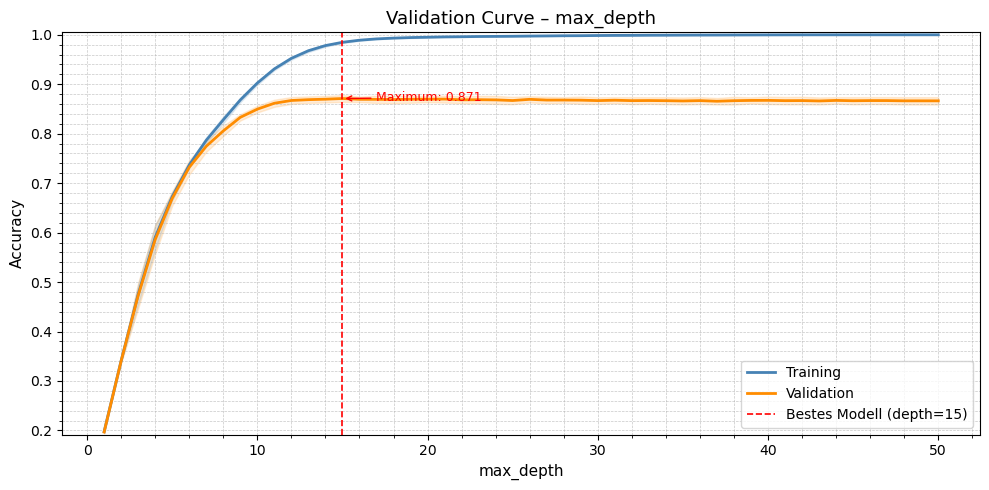

In [11]:
from sklearn.model_selection import validation_curve
import numpy as np
import matplotlib.pyplot as plt

param_range = range(1, 51)
train_scores, test_scores = validation_curve(
    DecisionTreeClassifier(random_state=42),
    X_train, y_train,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
train_mean = np.mean(train_scores, axis=1)
test_mean  = np.mean(test_scores,  axis=1)

# Optimalen Punkt finden
best_depth = param_range[np.argmax(test_mean)]
best_score = np.max(test_mean)

fig, ax = plt.subplots(figsize=(10, 5))

# Linien
ax.plot(param_range, train_mean, label='Training',  color='steelblue',  linewidth=2)
ax.plot(param_range, test_mean,  label='Validation', color='darkorange', linewidth=2)

# Konfidenzband (Streuung sichtbar machen)
train_std = np.std(train_scores, axis=1)
test_std  = np.std(test_scores,  axis=1)
ax.fill_between(param_range, train_mean - train_std, train_mean + train_std,
                alpha=0.15, color='steelblue')
ax.fill_between(param_range, test_mean  - test_std,  test_mean  + test_std,
                alpha=0.15, color='darkorange')

# Optimum markieren
ax.axvline(best_depth, color='red', linestyle='--', linewidth=1.2, label=f'Bestes Modell (depth={best_depth})')
ax.annotate(f'Maximum: {best_score:.3f}',
            xy=(best_depth, best_score),
            xytext=(best_depth + 2, best_score - 0.005),
            arrowprops=dict(arrowstyle='->', color='red'),
            color='red', fontsize=9)

# Y-Achse eng skalieren → Abwärtstrend wird viel deutlicher!
y_min = min(train_mean.min(), test_mean.min()) - 0.005
y_max = max(train_mean.max(), test_mean.max()) + 0.005
ax.set_ylim(y_min, y_max)

# Raster
ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
ax.minorticks_on()

ax.set_xlabel('max_depth', fontsize=11)
ax.set_ylabel('Accuracy', fontsize=11)
ax.set_title('Validation Curve – max_depth', fontsize=13)
ax.legend()

plt.tight_layout()
plt.savefig("Lernkurve_max_depth.jpg", bbox_inches="tight", dpi=150)
plt.show()

Das Optimum für `max_depth` liegt für die Testgenauigkeit bei 15. Das verdeutlicht anhand eines Beispielparameters, dass eine Anpassung zu besseren Testergebnissen führt und die Hyperparameter optimiert werden sollten, um Overfitting entgegenzuwirken.

### Kreuzvalidierung
Hyperparameter optimieren anhand von RandomizedSearchCV, da dieses alle Wechselwirkungen der Hyperparameter mit betrachtet. Die Rechenzeit wird im Vergleich zu GridSearchCV optimiert.

In [6]:
# Cross‑Validation definieren
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
n_iter_search = 60

# Parameterraum
param_dist = {
    "max_depth": list(range(5, 31, 5)) + [None], 
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "criterion": ["gini", "entropy"],
    "max_features": [None, "sqrt", "log2"],
    "ccp_alpha": [0.0, 1e-4, 5e-4, 1e-3, 5e-3]
}



# RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=n_iter_search,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=0                    
)

random_search.fit(X_train, y_train)

# Zusammenfassung der Ergebnisse
print("Beste gefundene Parameter")
print(random_search.best_params_)
print(f"Bester f1_macro-Score (Mittelwert über CV): {random_search.best_score_:.4f}\n")

# Top‑10 Ergebnisse als DataFrame anzeigen
results_df = pd.DataFrame(random_search.cv_results_)
top10 = results_df.nlargest(10, 'mean_test_score')[
    ['param_max_depth', 'param_min_samples_split', 'param_min_samples_leaf',
     'param_criterion', 'param_max_features', 'param_ccp_alpha',
     'mean_test_score', 'std_test_score']
]
print("Top‑10 Parameterkombinationen")
print(top10.to_string(index=False))

Beste gefundene Parameter
{'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 15, 'criterion': 'entropy', 'ccp_alpha': 0.0001}
Bester f1_macro-Score (Mittelwert über CV): 0.8758

Top‑10 Parameterkombinationen
param_max_depth  param_min_samples_split  param_min_samples_leaf param_criterion param_max_features  param_ccp_alpha  mean_test_score  std_test_score
             15                        2                       2         entropy               None           0.0001         0.875774        0.002933
             15                       10                       4         entropy               None           0.0001         0.874569        0.002828
             25                       10                       4         entropy               None           0.0000         0.873903        0.002504
             15                        2                       8         entropy               None           0.0001         0.872410        0.002996
          

#### Verworfen

Auch hier keine Erkentnisse durch die Visualisierung gewonnen.

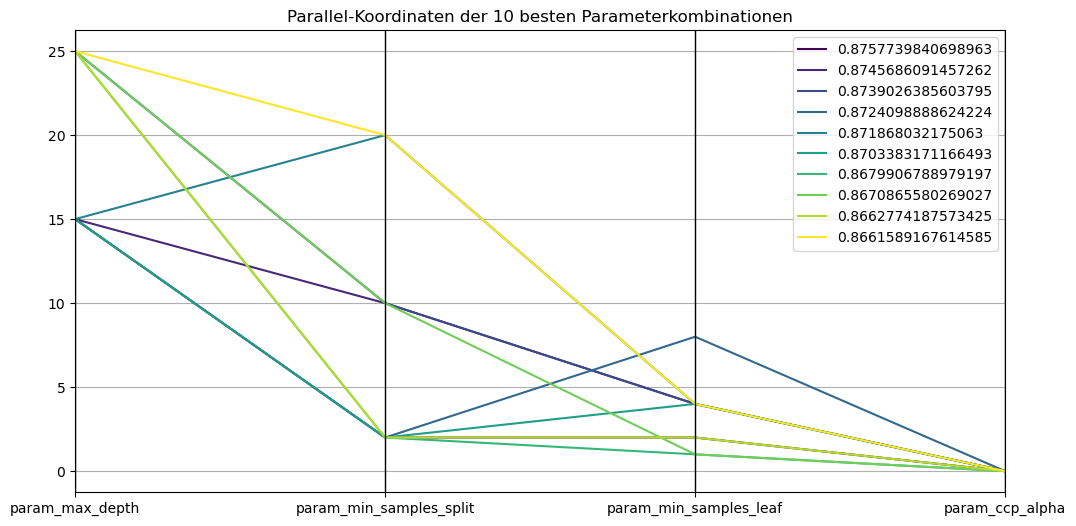

In [7]:
from pandas.plotting import parallel_coordinates

# Nur die 10 besten Kombinationen
top10 = results_df.nlargest(10, 'mean_test_score')

# Parameter müssen numerisch sein – ggf. kodieren
top10_plot = top10[['param_max_depth', 'param_min_samples_split',
                    'param_min_samples_leaf', 'param_ccp_alpha',
                    'mean_test_score']].copy()
# Kategoriale Parameter ignorieren wir hier der Einfachheit halber

plt.figure(figsize=(12, 6))
parallel_coordinates(top10_plot, 'mean_test_score', colormap='viridis')
plt.title('Parallel-Koordinaten der 10 besten Parameterkombinationen')
plt.legend(loc='upper right')
plt.savefig("Parallel-Koordinaten der 10 besten Parameterkombinationen.jpg", bbox_inches="tight")
plt.show()

## Entscheidungsbaum mit optimierten Parametern

Modell Trainieren anhand gefundener optimalen Parametern

In [8]:
# Bestes Modell mit den gefundenen Hyperparametern erstellen
opt_tree = DecisionTreeClassifier(**random_search.best_params_, random_state=42)
opt_tree.fit(X_train, y_train)

y_pred_opt = opt_tree.predict(X_test)
accuracy_opt = accuracy_score(y_test, y_pred_opt)

print("Optimierte Parameter:" ,opt_tree.get_params())
print()

# Gewählte Parameter
print("Tatsächliche Tiefe des Baums:", opt_tree.get_depth())
print("Anzahl der Blätter:", opt_tree.get_n_leaves())
print()

# Ergebnisse Test & Train mit optimierten Parametern
y_train_pred_opt = opt_tree.predict(X_train)
train_accuracy_opt = accuracy_score(y_train, y_train_pred_opt)

y_pred_opt = opt_tree.predict(X_test)
test_accuracy_opt = accuracy_score(y_test, y_pred_opt)

print("Accuracy Training:", round(train_accuracy_opt, 4))
print("Accuracy Test:", round(test_accuracy_opt, 4))
print("Differenz:", round(train_accuracy_opt - test_accuracy_opt, 4))
print()

Optimierte Parameter: {'ccp_alpha': 0.0001, 'class_weight': None, 'criterion': 'entropy', 'max_depth': 15, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

Tatsächliche Tiefe des Baums: 15
Anzahl der Blätter: 2031

Accuracy Training: 0.9738
Accuracy Test: 0.8891
Differenz: 0.0847



**Visualisierung des Baums**

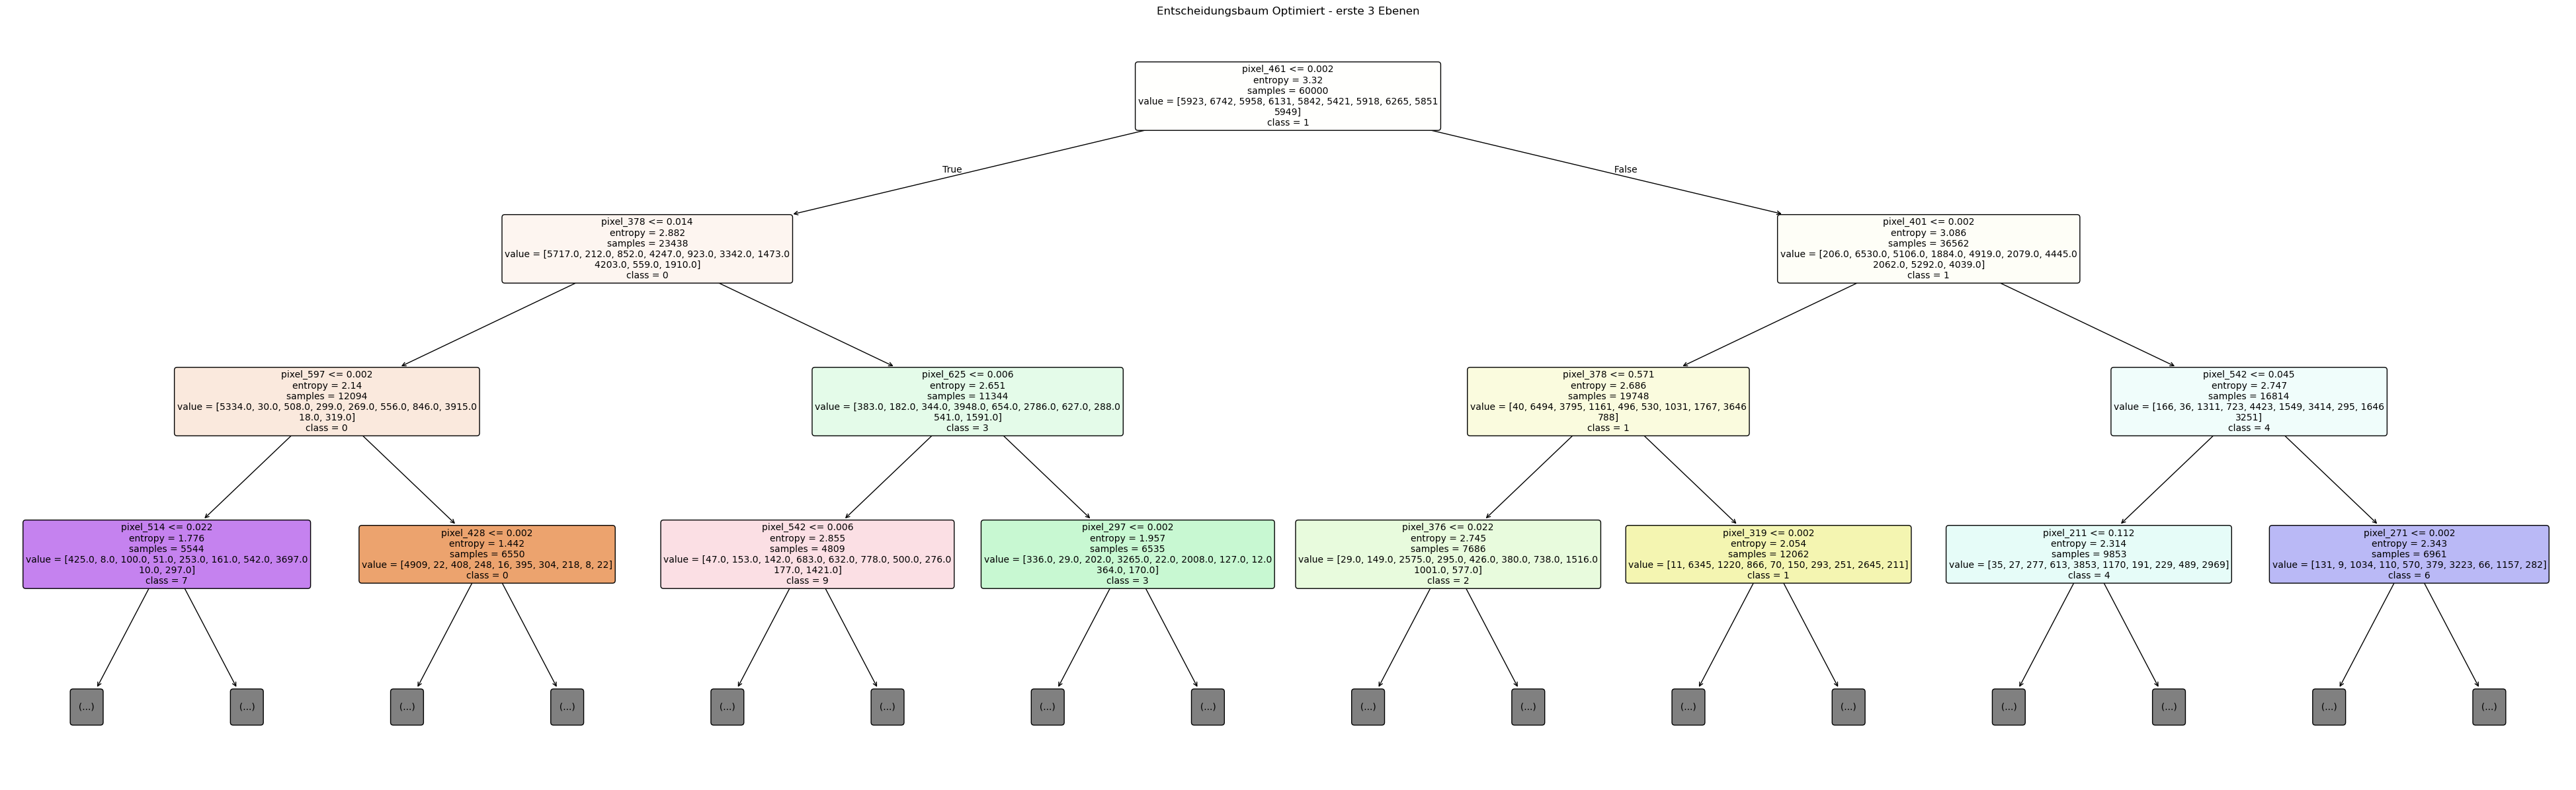

In [9]:
# Nur die ersten 3 Ebenen anzeigen
plt.figure(figsize=(50, 15))
plot_tree(opt_tree, 
          max_depth=3,       
          feature_names=[f'pixel_{i}' for i in range(784)], 
          class_names=[str(i) for i in range(10)],          
          filled=True,         
          rounded=True,         
          fontsize=10)
plt.title('Entscheidungsbaum Optimiert - erste 3 Ebenen')
plt.savefig("entscheidungsbaum Optimiert.jpg", bbox_inches="tight")
plt.show()

### Genauere Analyse 

Classification Report

In [10]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_opt, digits=3))

              precision    recall  f1-score   support

           0      0.913     0.942     0.927       980
           1      0.949     0.976     0.963      1135
           2      0.871     0.883     0.877      1032
           3      0.850     0.867     0.859      1010
           4      0.884     0.878     0.881       982
           5      0.843     0.839     0.841       892
           6      0.912     0.898     0.905       958
           7      0.912     0.898     0.905      1028
           8      0.862     0.836     0.849       974
           9      0.879     0.858     0.869      1009

    accuracy                          0.889     10000
   macro avg      0.888     0.887     0.887     10000
weighted avg      0.889     0.889     0.889     10000



Alle Klassen verbessern sich im Vergleich zum Standardmodell. Der größte Sprung zeigt sich bei den zuvor schwachen Klassen.

#### Importance einzelner Pixel

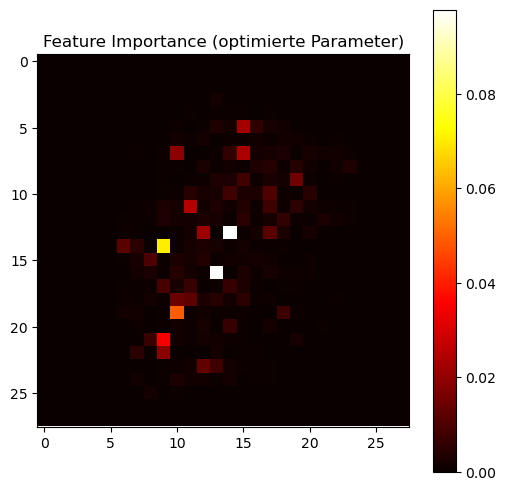

In [11]:
importances = opt_tree.feature_importances_
plt.figure(figsize=(6,6))
plt.imshow(importances.reshape(28,28), cmap='hot')
plt.colorbar()
plt.title('Feature Importance (optimierte Parameter)')
plt.savefig("Feature Importance (Optimiert).jpg", bbox_inches="tight")
plt.show()

Im optimierten Modell sind die Feature Importances stärker auf wenige zentrale Pixel konzentriert. Die Streuung ist geringer als beim Standardmodell.

#### ROC Kurve

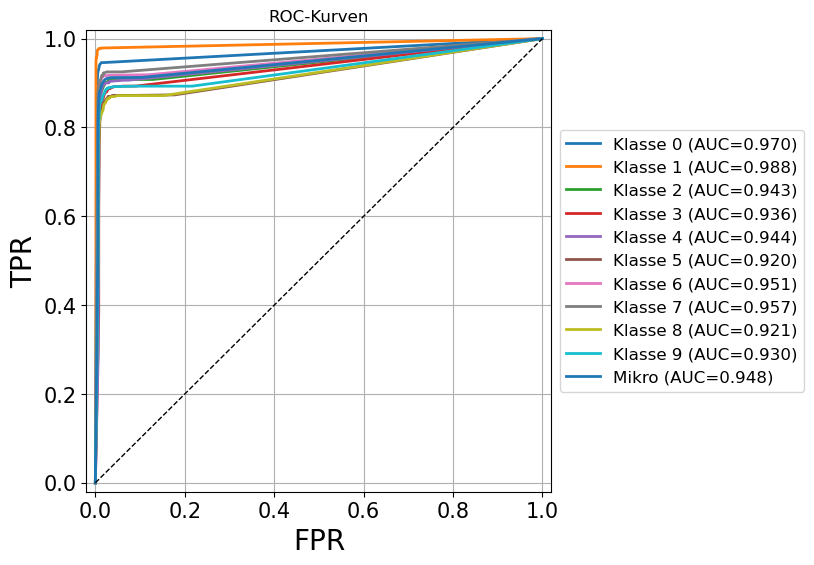

In [12]:
from sklearn.metrics import roc_curve, auc

# Wahrscheinlichkeiten
y_proba = opt_tree.predict_proba(X_test)
n_classes = len(opt_tree.classes_)

# Listen für ROC-Kurven
fpr_list, tpr_list, labels = [], [], []

# Für jede Klasse One-vs-Rest ROC
for i in range(n_classes):
    y_bin = (y_test == i).astype(int)
    fpr_i, tpr_i, _ = roc_curve(y_bin, y_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    fpr_list.append(fpr_i)
    tpr_list.append(tpr_i)
    labels.append(f'Klasse {i} (AUC={auc_i:.3f})')

# Mikro-Mittelung
y_test_bin = np.eye(n_classes)[y_test]  # One-Hot
fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_proba.ravel())
auc_micro = auc(fpr_micro, tpr_micro)
fpr_list.append(fpr_micro)
tpr_list.append(tpr_micro)
labels.append(f'Mikro (AUC={auc_micro:.3f})')

# Plot mit unsichtbaren Markern (markersize=0)
# Erzeuge data_style: [markersize, linewidth] – markersize=0, linewidth=2
data_style = [[0, 2] for _ in range(len(fpr_list))]

plot_res_roc(
    fpr_list, tpr_list,
    is_data_list=True,
    data_labels=labels,
    data_style=data_style,
    pos_legend='lower right'
)
plt.title('ROC-Kurven')
plt.savefig("ROC-Kurven.jpg", bbox_inches="tight")
plt.show()

Peer-Feedback Anpassung

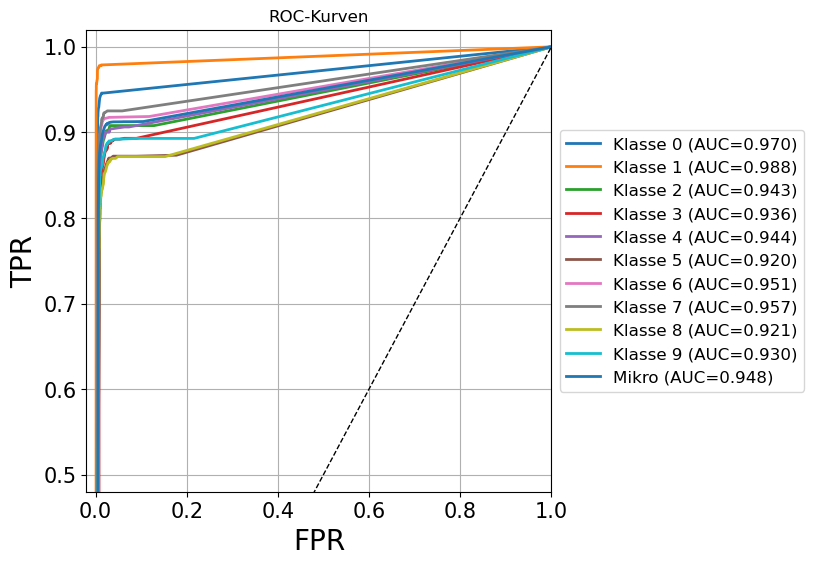

In [13]:
from sklearn.metrics import roc_curve, auc

# Wahrscheinlichkeiten
y_proba = opt_tree.predict_proba(X_test)
n_classes = len(opt_tree.classes_)

# Listen für ROC-Kurven
fpr_list, tpr_list, labels = [], [], []

# Für jede Klasse One-vs-Rest ROC
for i in range(n_classes):
    y_bin = (y_test == i).astype(int)
    fpr_i, tpr_i, _ = roc_curve(y_bin, y_proba[:, i])
    auc_i = auc(fpr_i, tpr_i)
    fpr_list.append(fpr_i)
    tpr_list.append(tpr_i)
    labels.append(f'Klasse {i} (AUC={auc_i:.3f})')

# Mikro-Mittelung
y_test_bin = np.eye(n_classes)[y_test]  # One-Hot
fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_proba.ravel())
auc_micro = auc(fpr_micro, tpr_micro)
fpr_list.append(fpr_micro)
tpr_list.append(tpr_micro)
labels.append(f'Mikro (AUC={auc_micro:.3f})')

# Plot mit unsichtbaren Markern (markersize=0)
# Erzeuge data_style: [markersize, linewidth] – markersize=0, linewidth=2
data_style = [[0, 2] for _ in range(len(fpr_list))]

plot_res_roc(
    fpr_list, tpr_list,
    is_data_list=True,
    data_labels=labels,
    data_style=data_style,
    pos_legend='lower right'
)
plt.title('ROC-Kurven')
plt.savefig("ROC-Kurven_Peerfeedback.jpg", bbox_inches="tight")
plt.xlim([-0.02, 1])
plt.ylim([0.48, 1.02])
plt.show()

#### Standard vs Optimiert

Es werden relevante Metriken gegenübergestellt.

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

metrics = pd.DataFrame({
    "Metric": [
        "Train Accuracy",
        "Test Accuracy",
        "Precision (macro)",
        "Recall (macro)",
        "F1 Score (macro)",
        "ROC AUC (macro)"
    ],
    "Standard": [
        train_accuracy_std,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro"),
        recall_score(y_test, y_pred, average="macro"),
        f1_score(y_test, y_pred, average="macro"),
        roc_auc_score(y_test, tree.predict_proba(X_test), multi_class="ovr", average="macro")
    ],
    "Optimiert": [
        train_accuracy_opt,
        accuracy_score(y_test, y_pred_opt),
        precision_score(y_test, y_pred_opt, average="macro"),
        recall_score(y_test, y_pred_opt, average="macro"),
        f1_score(y_test, y_pred_opt, average="macro"),
        roc_auc_score(y_test, opt_tree.predict_proba(X_test), multi_class="ovr", average="macro")
    ]
})

# Differenz berechnen
metrics["Δ (Optimiert - Standard)"] = metrics["Optimiert"] - metrics["Standard"]
metrics = metrics.round(3)

print(metrics)

              Metric  Standard  Optimiert  Δ (Optimiert - Standard)
0     Train Accuracy     1.000      0.974                    -0.026
1      Test Accuracy     0.875      0.889                     0.014
2  Precision (macro)     0.874      0.888                     0.014
3     Recall (macro)     0.874      0.887                     0.014
4   F1 Score (macro)     0.874      0.887                     0.014
5    ROC AUC (macro)     0.930      0.946                     0.016


Höhere Testgenauigkeit beim optimierten Modell und eine niedrigere Trainingsgenauigkeit zeigen, dass das optimierte Modell besser generalisiert (weniger Overfitting). Auch die anderen relevanten Messwerte haben sich verbessert. Die Optimierung war somit erfolgreich.